In [1]:


import numpy as np, pandas as pd, tensorflow as tf
from numpy.lib.stride_tricks import sliding_window_view   
from sklearn import metrics                                
from sklearn.pipeline import Pipeline                      
from sklearn.compose import TransformedTargetRegressor     
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor           
from xgboost import XGBRegressor
from tensorflow.keras import Sequential, Input, layers, callbacks
from reservoirpy.nodes import Reservoir, Ridge             
from dieboldmariano import dm_test                        


seed = 23
tf.keras.utils.set_random_seed(seed)  
horizonResults = {}                    

In [2]:
h = 1          # forecast horizon in months: 1, 3 or 6
window = 12

In [3]:
rawData = (pd.read_csv("clean_output/combined.csv", parse_dates=["date"])
             .rename(columns={"exchange rate": "exchange_rate"})   # remove the space in the column name
             .dropna()
             .query("'2002-01-01' <= date <= '2021-12-01'")        # 240 months, as in R
             .reset_index(drop=True))

# Differenced data, as in R: CPI stays as it is (m/m inflation); cocoa, crude and USD/GHS are first-differenced
diffData = rawData.copy()
diffData["cocoa"] = rawData["cocoa"].diff()
diffData["crude"] = rawData["crude"].diff()
diffData["exchange_rate"] = rawData["exchange_rate"].diff()

colNames = ["cpi", "cocoa", "crude", "exchange_rate"]
xLev = rawData[colNames].iloc[1:].to_numpy()          # raw data (levels), 239 months
xDiff = diffData[colNames].iloc[1:].to_numpy()        # differenced data, 239 months
fx = rawData["exchange_rate"].iloc[1:].to_numpy()     # USD/GHS levels (used to undifference and to evaluate)

n, nTrain = len(fx), 191          # first 191 months for training, as in R
nTest = n - nTrain                # last 48 for testing
maseScale = diffData["exchange_rate"].iloc[1:nTrain + 1].abs().mean()   # R's maseDen = mean(abs(yTrain))
print(n, nTrain, nTest)

239 191 48


In [4]:
# Each sample is the last 12 months of all 4 series, shape (samples, 12, 4), for each data version
xwLev = sliding_window_view(xLev, window, axis=0).transpose(0, 2, 1)[:n - h - window + 1]
xwDiff = sliding_window_view(xDiff, window, axis=0).transpose(0, 2, 1)[:n - h - window + 1]

origin = fx[window - 1:n - h]                  # USD/GHS level at the end of each window
actualAll = fx[window - 1 + h:]                # USD/GHS level h months later
oAll = np.arange(window - 1, n - h)            # position of each origin (for the drift)

# Targets: the levels models predict the level; the differenced models predict the h-month change
yLev = actualAll
yDiff = actualAll - origin

# Time-ordered split. [h-1:] keeps test origins from the last training month onward, as R's tsCV does
xTrainLev, xTestLev = xwLev[:-nTest], xwLev[-nTest:][h - 1:]
xTrainDiff, xTestDiff = xwDiff[:-nTest], xwDiff[-nTest:][h - 1:]
yTrainLev, yTrainDiff = yLev[:-nTest], yDiff[:-nTest]

actualTrain, actual = actualAll[:-nTest], actualAll[-nTest:][h - 1:]
originTrain, originTest = origin[:-nTest], origin[-nTest:][h - 1:]
oTrain, oTest = oAll[:-nTest], oAll[-nTest:][h - 1:]

# SVR, XGBoost and NARX need 2D input, so flatten each (12, 4) window into 48 columns
xTrainLevFlat = xTrainLev.reshape(len(xTrainLev), -1)
xTestLevFlat = xTestLev.reshape(len(xTestLev), -1)
xTrainDiffFlat = xTrainDiff.reshape(len(xTrainDiff), -1)
xTestDiffFlat = xTestDiff.reshape(len(xTestDiff), -1)

# ESN targets (one per month): level h months ahead, or change over h months
eLev = fx[h:]
eDiff = fx[h:] - fx[:-h]

predsLev = {}                     # test forecasts of the models fitted on raw data
predsDiff = {}                    # test forecasts (as changes) of the models fitted on differenced data
print(xTrainLev.shape, xTestLev.shape)

(179, 12, 4) (48, 12, 4)


In [5]:
svrLev = TransformedTargetRegressor(
    regressor=Pipeline([("scaler", StandardScaler()),
                      ("model", SVR(
            kernel="rbf",
            C=100,
            epsilon=0.01,
            gamma="scale",
            tol=1e-4,
            cache_size=1000
        ))]),
    transformer=StandardScaler())
svrLev.fit(xTrainLevFlat, yTrainLev)
predsLev["SVR"] = svrLev.predict(xTestLevFlat)

svrDiff = TransformedTargetRegressor(
    regressor=Pipeline([("scaler", StandardScaler()),
                      ("model", SVR(
            kernel="rbf",
            C=100,
            epsilon=0.01,
            gamma="scale",
            tol=1e-4,
            cache_size=1000
        ))]),
    transformer=StandardScaler())
svrDiff.fit(xTrainDiffFlat, yTrainDiff)
predsDiff["SVR"] = svrDiff.predict(xTestDiffFlat)

In [6]:
xgbLev = TransformedTargetRegressor(
    regressor=Pipeline([("scaler", StandardScaler()),
                        ("model", XGBRegressor(n_estimators=2000,
                                               max_depth=2,
                                               learning_rate=0.01,
                                               random_state=seed,
                                               n_jobs=1))]),
    transformer=StandardScaler())
xgbLev.fit(xTrainLevFlat, yTrainLev)

xgbDiff = TransformedTargetRegressor(
    regressor=Pipeline([("scaler", StandardScaler()),
                        ("model", XGBRegressor(n_estimators=2000,
                                               max_depth=2,
                                               learning_rate=0.01,
                                               random_state=seed,
                                               n_jobs=1))]),
    transformer=StandardScaler())
xgbDiff.fit(xTrainDiffFlat, yTrainDiff)

TransformedTargetRegressor(regressor=Pipeline(steps=[('scaler',
                                                      StandardScaler()),
                                                     ('model',
                                                      XGBRegressor(base_score=None,
                                                                   booster=None,
                                                                   callbacks=None,
                                                                   colsample_bylevel=None,
                                                                   colsample_bynode=None,
                                                                   colsample_bytree=None,
                                                                   device=None,
                                                                   early_stopping_rounds=None,
                                                                   enable_categorical=False,
                                                                   eval_metric=None,
                                                                   feature_types=None,
                                                                   feature_weights=None,
                                                                   gamma=None,
                                                                   grow...y=None,
                                                                   importance_type=None,
                                                                   interaction_constraints=None,
                                                                   learning_rate=0.01,
                                                                   max_bin=None,
                                                                   max_cat_threshold=None,
                                                                   max_cat_to_onehot=None,
                                                                   max_delta_step=None,
                                                                   max_depth=2,
                                                                   max_leaves=None,
                                                                   min_child_weight=None,
                                                                   missing=nan,
                                                                   monotone_constraints=None,
                                                                   multi_strategy=None,
                                                                   n_estimators=2000,
                                                                   n_jobs=1,
                                                                   num_parallel_tree=None, ...))]),
                           transformer=StandardScaler())

In [7]:
predsLev["XGBoost"] = xgbLev.predict(xTestLevFlat)
predsDiff["XGBoost"] = xgbDiff.predict(xTestDiffFlat)

In [8]:
narxLev = TransformedTargetRegressor(
    regressor=Pipeline([("scaler", StandardScaler()),
                        ("model", MLPRegressor(hidden_layer_sizes=(64,32,16),
                                               alpha=0.0003,
                                               max_iter=2000,
                                               random_state=seed))]),
    transformer=StandardScaler())
narxLev.fit(xTrainLevFlat, yTrainLev)
predsLev["NARX"] = narxLev.predict(xTestLevFlat)

narxDiff = TransformedTargetRegressor(
    regressor=Pipeline([("scaler", StandardScaler()),
                        ("model", MLPRegressor(hidden_layer_sizes=(64,32,16),
                                               alpha=0.0003,
                                               max_iter=2000,
                                               random_state=seed))]),
    transformer=StandardScaler())
narxDiff.fit(xTrainDiffFlat, yTrainDiff)
predsDiff["NARX"] = narxDiff.predict(xTestDiffFlat)

In [9]:
# Scalers are fit on training data only, so nothing from the test period leaks in.
# --- raw data ---
xScalerLev, yScalerLev = StandardScaler(), StandardScaler()
xTrainLevS = xScalerLev.fit_transform(xTrainLevFlat).reshape(xTrainLev.shape)
xTestLevS = xScalerLev.transform(xTestLevFlat).reshape(xTestLev.shape)
yTrainLevS = yScalerLev.fit_transform(yTrainLev.reshape(-1, 1))

tf.keras.utils.set_random_seed(seed)
lstmLev = Sequential([
    Input(shape=(window, 4)),

    layers.LSTM(128, return_sequences=True),
    layers.Dropout(0.1),

    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.1),

    layers.LSTM(32, return_sequences=True),

    layers.LSTM(16),

    layers.Dense(1)
])
lstmLev.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss="mse")
lstmLev.fit(xTrainLevS, yTrainLevS,
         epochs=300, batch_size=8,
         validation_split=0.15,
         shuffle=False,
         callbacks=[callbacks.EarlyStopping(patience=12, restore_best_weights=True, monitor='val_loss')],
         verbose=0)

# --- differenced data ---
xScalerDiff, yScalerDiff = StandardScaler(), StandardScaler()
xTrainDiffS = xScalerDiff.fit_transform(xTrainDiffFlat).reshape(xTrainDiff.shape)
xTestDiffS = xScalerDiff.transform(xTestDiffFlat).reshape(xTestDiff.shape)
yTrainDiffS = yScalerDiff.fit_transform(yTrainDiff.reshape(-1, 1))

tf.keras.utils.set_random_seed(seed)
lstmDiff = Sequential([
    Input(shape=(window, 4)),

    layers.LSTM(128, return_sequences=True),
    layers.Dropout(0.1),

    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.1),

    layers.LSTM(32, return_sequences=True),

    layers.LSTM(16),

    layers.Dense(1)
])
lstmDiff.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss="mse")
lstmDiff.fit(xTrainDiffS, yTrainDiffS,
         epochs=300, batch_size=8,
         validation_split=0.15,
         shuffle=False,
         callbacks=[callbacks.EarlyStopping(patience=12, restore_best_weights=True, monitor='val_loss')],
         verbose=0)

In [10]:
predsLev["LSTM"] = yScalerLev.inverse_transform(lstmLev.predict(xTestLevS, verbose=0)).ravel()
predsDiff["LSTM"] = yScalerDiff.inverse_transform(lstmDiff.predict(xTestDiffS, verbose=0)).ravel()

In [11]:
# --- raw data ---
xsLev = StandardScaler().fit(xLev[:nTrain]).transform(xLev)           # scaler fit on training months only
yScEsnLev = StandardScaler().fit(eLev[:nTrain - h].reshape(-1, 1))

esnLev = Reservoir(200, sr=0.9, lr=1, seed=seed) >> Ridge(ridge=0.001)   # tune ridge, sr, lr by hand here
esnLev.fit(xsLev[:nTrain - h], yScEsnLev.transform(eLev[:nTrain - h].reshape(-1, 1)), warmup=window)

esnLev.reset()                                                        # start from a zero state
esnOutLev = yScEsnLev.inverse_transform(esnLev.run(xsLev[:n - h])).ravel()
predsLev["ESN"] = esnOutLev[nTrain - 1:]                              # test origins start at the last training month

# --- differenced data ---
xsDiff = StandardScaler().fit(xDiff[:nTrain]).transform(xDiff)
yScEsnDiff = StandardScaler().fit(eDiff[:nTrain - h].reshape(-1, 1))

esnDiff = Reservoir(200, sr=0.9, lr=1, seed=seed) >> Ridge(ridge=0.001)  # tune ridge, sr, lr by hand here
esnDiff.fit(xsDiff[:nTrain - h], yScEsnDiff.transform(eDiff[:nTrain - h].reshape(-1, 1)), warmup=window)

esnDiff.reset()                                                       # start from a zero state
esnOutDiff = yScEsnDiff.inverse_transform(esnDiff.run(xsDiff[:n - h])).ravel()
predsDiff["ESN"] = esnOutDiff[nTrain - 1:]

In [12]:
# Raw-data models already predict USD/GHS
forecastsLev = pd.DataFrame(predsLev)
forecastsLev["RW"] = originTest                                               # random walk
forecastsLev["RW drift"] = originTest + h * (originTest - fx[0]) / oTest      # drift re-estimated at each origin

# Differenced models predict a change: undifference by adding the last observed level
forecastsDiff = pd.DataFrame(predsDiff).add(originTest, axis=0)
forecastsDiff["RW"] = originTest
forecastsDiff["RW drift"] = originTest + h * (originTest - fx[0]) / oTest

In [13]:
testMetricsLev = pd.DataFrame({
    "ME":   forecastsLev.apply(lambda f: (actual - f).mean()),
    "RMSE": forecastsLev.apply(lambda f: metrics.root_mean_squared_error(actual, f)),
    "MAE":  forecastsLev.apply(lambda f: metrics.mean_absolute_error(actual, f))})
testMetricsLev["MASE"] = testMetricsLev["MAE"] / maseScale
testMetricsLev["RelRMSE"] = testMetricsLev["RMSE"] / testMetricsLev.loc["RW drift", "RMSE"]   # <1 beats RW with drift

# Directional accuracy: did the forecast get the up/down move right?
actualDir = np.sign(actual - originTest)
testMetricsLev["DirAcc"] = forecastsLev.apply(lambda f: metrics.accuracy_score(actualDir, np.sign(f - originTest)))
testMetricsLev.loc["RW", "DirAcc"] = np.nan        # a flat forecast has no direction

# Diebold-Mariano p-value against RW with drift
testMetricsLev["DM_p"] = forecastsLev.drop(columns="RW drift").apply(
    lambda f: dm_test(actual, f.to_numpy(), forecastsLev["RW drift"].to_numpy(), h=h)[1])

print(f"--- TEST-SET METRICS (cedis), RAW data, h = {h} ---")
testMetricsLev.round(4)

--- TEST-SET METRICS (cedis), RAW data, h = 1 ---


,ME,RMSE,MAE,MASE,RelRMSE,DirAcc,DM_p
SVR,1.5306,1.7414,1.5306,47.1511,26.9642,0.1250,0.0000
XGBoost,1.1466,1.2406,1.1466,35.3222,19.2107,0.1250,0.0000
NARX,-0.0896,0.1831,0.1362,4.1960,2.8354,0.7292,0.0001
LSTM,1.3107,1.3762,1.3107,40.3791,21.3095,0.1250,0.0000
ESN,0.8755,1.0369,0.8799,27.1066,16.0555,0.1875,0.0000
RW,0.0321,0.0711,0.0471,1.4505,1.1004,NaN,0.0301
RW drift,0.0109,0.0646,0.0401,1.2357,1.0000,0.7500,NaN


In [14]:
testMetricsDiff = pd.DataFrame({
    "ME":   forecastsDiff.apply(lambda f: (actual - f).mean()),
    "RMSE": forecastsDiff.apply(lambda f: metrics.root_mean_squared_error(actual, f)),
    "MAE":  forecastsDiff.apply(lambda f: metrics.mean_absolute_error(actual, f))})
testMetricsDiff["MASE"] = testMetricsDiff["MAE"] / maseScale
testMetricsDiff["RelRMSE"] = testMetricsDiff["RMSE"] / testMetricsDiff.loc["RW drift", "RMSE"]

testMetricsDiff["DirAcc"] = forecastsDiff.apply(lambda f: metrics.accuracy_score(actualDir, np.sign(f - originTest)))
testMetricsDiff.loc["RW", "DirAcc"] = np.nan

testMetricsDiff["DM_p"] = forecastsDiff.drop(columns="RW drift").apply(
    lambda f: dm_test(actual, f.to_numpy(), forecastsDiff["RW drift"].to_numpy(), h=h)[1])

print(f"--- TEST-SET METRICS (cedis), DIFFERENCED data, h = {h} ---")
testMetricsDiff.round(4)

--- TEST-SET METRICS (cedis), DIFFERENCED data, h = 1 ---


,ME,RMSE,MAE,MASE,RelRMSE,DirAcc,DM_p
SVR,-0.0030,0.0812,0.0545,1.6794,1.2580,0.6667,0.0680
XGBoost,-0.0000,0.0794,0.0534,1.6446,1.2298,0.6875,0.0421
NARX,0.0077,0.0866,0.0637,1.9631,1.3410,0.5000,0.0168
LSTM,0.0128,0.0646,0.0400,1.2318,0.9996,0.7500,0.9094
ESN,0.0196,0.1862,0.1537,4.7356,2.8828,0.4167,0.0000
RW,0.0321,0.0711,0.0471,1.4505,1.1004,NaN,0.0301
RW drift,0.0109,0.0646,0.0401,1.2357,1.0000,0.7500,NaN


In [15]:
# Train forecasts (in-sample fitted values) in USD/GHS
trainFcLev = pd.DataFrame({
    "SVR":     svrLev.predict(xTrainLevFlat),
    "XGBoost": xgbLev.predict(xTrainLevFlat),
    "NARX":    narxLev.predict(xTrainLevFlat),
    "LSTM":    yScalerLev.inverse_transform(lstmLev.predict(xTrainLevS, verbose=0)).ravel(),
    "ESN":     esnOutLev[:nTrain - h][window - 1:]})        # drop warmup rows to align with the windows
trainFcLev["RW"] = originTrain
trainFcLev["RW drift"] = originTrain + h * (originTrain - fx[0]) / oTrain

trainFcDiff = pd.DataFrame({
    "SVR":     svrDiff.predict(xTrainDiffFlat),
    "XGBoost": xgbDiff.predict(xTrainDiffFlat),
    "NARX":    narxDiff.predict(xTrainDiffFlat),
    "LSTM":    yScalerDiff.inverse_transform(lstmDiff.predict(xTrainDiffS, verbose=0)).ravel(),
    "ESN":     esnOutDiff[:nTrain - h][window - 1:]}).add(originTrain, axis=0)    # undifference
trainFcDiff["RW"] = originTrain
trainFcDiff["RW drift"] = originTrain + h * (originTrain - fx[0]) / oTrain
print(trainFcLev.shape, trainFcDiff.shape)

(179, 7) (179, 7)


In [16]:
trainMetricsLev = pd.DataFrame({
    "ME":   trainFcLev.apply(lambda f: (actualTrain - f).mean()),
    "RMSE": trainFcLev.apply(lambda f: metrics.root_mean_squared_error(actualTrain, f)),
    "MAE":  trainFcLev.apply(lambda f: metrics.mean_absolute_error(actualTrain, f))})
trainMetricsLev["MASE"] = trainMetricsLev["MAE"] / maseScale
trainMetricsLev["Test/Train RMSE"] = testMetricsLev["RMSE"] / trainMetricsLev["RMSE"]   # train-test gap

trainMetricsDiff = pd.DataFrame({
    "ME":   trainFcDiff.apply(lambda f: (actualTrain - f).mean()),
    "RMSE": trainFcDiff.apply(lambda f: metrics.root_mean_squared_error(actualTrain, f)),
    "MAE":  trainFcDiff.apply(lambda f: metrics.mean_absolute_error(actualTrain, f))})
trainMetricsDiff["MASE"] = trainMetricsDiff["MAE"] / maseScale
trainMetricsDiff["Test/Train RMSE"] = testMetricsDiff["RMSE"] / trainMetricsDiff["RMSE"]

print(f"--- TRAIN-SET METRICS (cedis), RAW data, h = {h} ---")
display(trainMetricsLev.round(4))
print(f"--- TRAIN-SET METRICS (cedis), DIFFERENCED data, h = {h} ---")
display(trainMetricsDiff.round(4))

--- TRAIN-SET METRICS (cedis), RAW data, h = 1 ---


,ME,RMSE,MAE,MASE,Test/Train RMSE
SVR,-0.0023,0.0114,0.0112,0.3465,152.3173
XGBoost,0.0000,0.0042,0.0028,0.0848,295.7228
NARX,-0.0039,0.0871,0.0637,1.9635,2.1018
LSTM,0.0375,0.1721,0.1068,3.2897,7.9985
ESN,-0.0008,0.0133,0.0068,0.2110,77.7271
RW,0.0199,0.0793,0.0339,1.0447,0.8960
RW drift,0.0108,0.0771,0.0325,1.0003,0.8382


--- TRAIN-SET METRICS (cedis), DIFFERENCED data, h = 1 ---


,ME,RMSE,MAE,MASE,Test/Train RMSE
SVR,-0.0002,0.0008,0.0008,0.0234,106.5882
XGBoost,0.0000,0.0087,0.0061,0.1880,9.0892
NARX,0.0000,0.0048,0.0015,0.0449,17.8669
LSTM,0.0017,0.0766,0.0358,1.1028,0.8428
ESN,-0.0003,0.0057,0.0036,0.1102,32.3789
RW,0.0199,0.0793,0.0339,1.0447,0.8960
RW drift,0.0108,0.0771,0.0325,1.0003,0.8382


<Axes: title={'center': 'USD/GHS: actual vs forecast (test set), Level data'}, xlabel='Test month', ylabel='USD/GHS'>

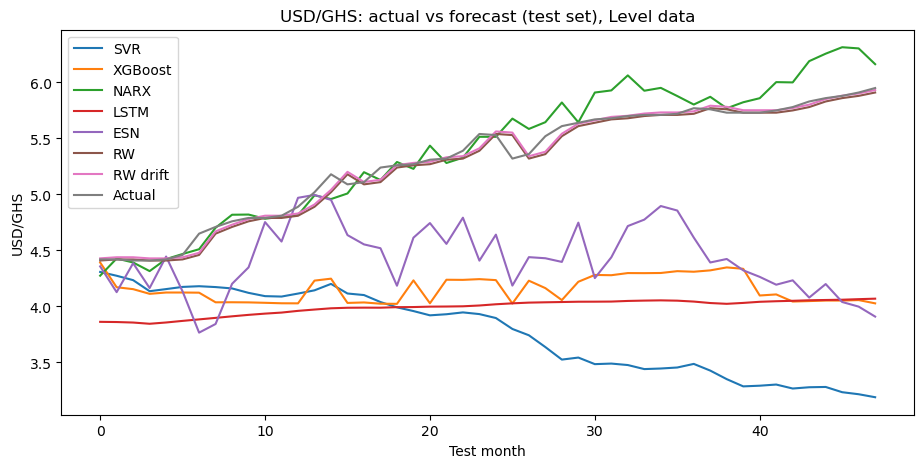

In [22]:
forecastsLev.assign(Actual=actual).plot(
    figsize=(11, 5), title=f"USD/GHS: actual vs forecast (test set), Level data",
    xlabel="Test month", ylabel="USD/GHS")

# import matplotlib
# matplotlib.rcParams["pdf.fonttype"] = 42
# matplotlib.rcParams["ps.fonttype"] = 42

# ax = forecastsLev.assign(Actual=actual).plot(
#     figsize=(4.7, 3.0), xlabel="Test month", ylabel="USD/GHS", fontsize=8
# )

# # different line style per series, actual rate in solid black
# styles = ["-", "--", ":", "-.", (0, (5, 1, 1, 1, 1, 1)), "-"]
# for line, ls in zip(ax.get_lines(), styles):
#     line.set_linestyle(ls)
# ax.get_lines()[-1].set_color("black")

# ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2),
#           ncol=3, fontsize=7, frameon=False)

# fig = ax.figure
# fig.savefig("Fig2a.pdf", bbox_inches="tight")
# fig.savefig("Fig2a.eps", bbox_inches="tight")
# # only if you must keep a bitmap:
# fig.savefig("Fig2a.png", dpi=600, bbox_inches="tight")



<Axes: title={'center': 'USD/GHS: actual vs forecast (test set), DIFFERENCED data'}, xlabel='Test month', ylabel='USD/GHS'>

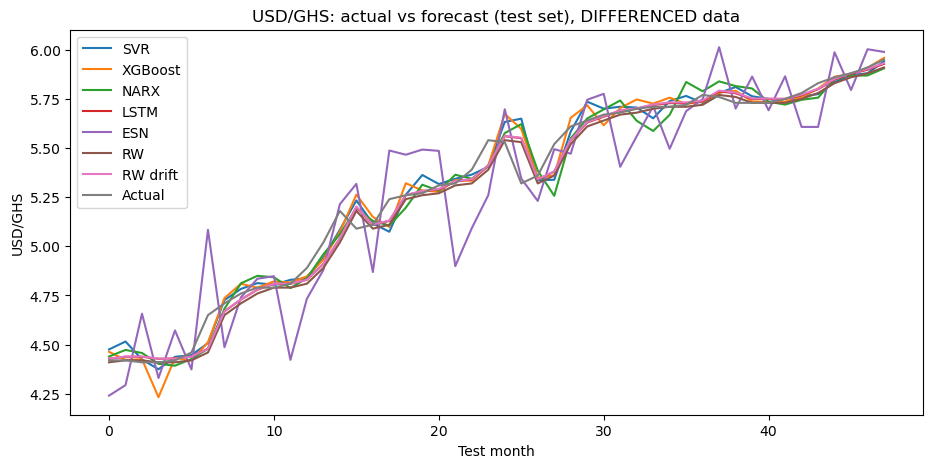

In [23]:
forecastsDiff.assign(Actual=actual).plot(
    figsize=(11, 5), title=f"USD/GHS: actual vs forecast (test set), DIFFERENCED data",
    xlabel="Test month", ylabel="USD/GHS")


# import matplotlib
# matplotlib.rcParams["pdf.fonttype"] = 42
# matplotlib.rcParams["ps.fonttype"] = 42

# ax = forecastsDiff.assign(Actual=actual).plot(
#     figsize=(4.7, 3.0), xlabel="Test month", ylabel="USD/GHS", fontsize=8
# )

# # different line style per series, actual rate in solid black
# styles = ["-", "--", ":", "-.", (0, (5, 1, 1, 1, 1, 1)), "-"]
# for line, ls in zip(ax.get_lines(), styles):
#     line.set_linestyle(ls)
# ax.get_lines()[-1].set_color("black")

# ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2),
#           ncol=3, fontsize=7, frameon=False)

# fig = ax.figure
# fig.savefig("Fig2b.pdf", bbox_inches="tight")
# fig.savefig("Fig2b.eps", bbox_inches="tight")

In [19]:
import sys
from importlib.metadata import version

# Distribution names as installed by pip (these differ from the import names for some packages)
pkgs = ["numpy", "pandas", "tensorflow", "scikit-learn", "xgboost",
        "reservoirpy", "dieboldmariano"]

print("Python", sys.version.split()[0])
for p in pkgs:
    print(f"{p}: {version(p)}")

Python 3.12.7
numpy: 1.26.4
pandas: 2.2.2
tensorflow: 2.20.0
scikit-learn: 1.5.1
xgboost: 3.2.0
reservoirpy: 0.4.2
dieboldmariano: 1.1.0
